
# Project Name : Netflix Executive Dashboard

## Selected Challenge - Challenge 5: Executive Dashboard for Netflix Management

### Business Question
What key performance indicators should Netflix executives monitor to understand movie viewing patterns, user ratings, genre preferences, and membership distribution?

## Project Objectives
The main objective of this project is to analyze Netflix movie ratings and viewing data and develop an executive dashboard to support Netflix management decisions.

The specific objectives are:

1. To examine the structure and quality of the Netflix dataset.
2. To clean and prepare the dataset for analysis.
3. To identify key performance indicators related to movies, ratings, genres, viewing activity, and membership.
4. To conduct exploratory data analysis (EDA) to identify meaningful patterns.
5. To create at least three meaningful visualizations.
6. To generate at least three business insights and recommendations for Netflix management.

## Dataset Overview
The dataset used in this project is `Netflix_Dataset.csv`.

It contains 500 observations and 11 columns describing movie information, viewing records, user ratings, and membership categories.

## Project Workflow
The project follows the Extract, Transform, Load (ETL) process, followed by exploratory data analysis, visualization, business insights, and conclusions.


**GitHub Repository:**  
https://github.com/YaqootRuby/Netflix-Executive-Dashboard-Sprint

**Project Type:** Netflix Data Analysis and Executive Reporting

**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn, Jupyter Notebook



## 1. Importing Required Libraries

- **pandas:** Used for loading, cleaning, transforming, and analyzing tabular data.
- **numpy:** Used for numerical operations and calculations.
- **matplotlib.pyplot:** Used for creating and customizing charts.
- **seaborn:** Used for creating statistical visualizations.



In [20]:

# Import pandas for data manipulation and analysis
import pandas as pd

# Import numpy for numerical calculations
import numpy as np

# Import matplotlib for creating visualizations
import matplotlib.pyplot as plt

# Import seaborn for statistical data visualization
import seaborn as sns

# Import display utilities for notebook dashboards
from IPython.display import display

# Confirm that the libraries are imported successfully
print("All required libraries imported successfully.")


All required libraries imported successfully.



## 2. Extract:
### Loading the Netflix Dataset

Extracting data from the Netflix CSV file and loading it into a pandas DataFrame.

Before performing any analysis, we need to access the raw dataset in Python.

A pandas DataFrame organizes data into rows and columns, making it easier to inspect, clean, transform, and analyze.

### Initial Data Inspection

It allows us to:
- Identify the total number of observations and variables.
- Understand the types of data stored in each column.
- Identify numerical and categorical variables.
- Examine basic statistical properties.
- Detect potential data quality issues.


In [21]:

# Read the Netflix CSV file
netflix_df = pd.read_csv("Netflix_Dataset.csv")

# Display the first five observations
netflix_df.head()


,Movie_id,Movie_Title,Genre,Year_of_release,Movie_duration,Watched_Country,Watched_date,User_Id,Ratings,Average_Ratings,Membership
0,M045,Star Soup,Animation,2001,88,Spain,2025-01-02,U0117,4,2.83,Standard
1,M006,Wedding Crashers Anonymous,Comedy,2014,102,France,2025-01-02,U0195,2,3.25,Basic
2,M044,Bubblewick,Animation,2006,104,United States,2025-01-06,U0071,3,2.80,Standard
3,M054,The Lantern Witch,Fantasy,2011,115,India,2025-01-07,U0057,4,3.23,Basic
4,M047,The Quiet Accountant,Crime,2024,132,Brazil,2025-01-12,U0093,4,3.14,Standard


In [22]:

# Display the number of rows and columns
print("Dataset Shape:", netflix_df.shape)

# Display the names of all columns
print("\nColumn Names:")
print(netflix_df.columns.tolist())

# Display data types and non-null counts
print("\nDataset Information:")
netflix_df.info()

# Display descriptive statistics for numerical columns
print("\nNumerical Summary:")
display(netflix_df.describe())

# Display descriptive statistics for categorical columns
print("\nCategorical Summary:")
display(netflix_df.describe(include="object"))


Dataset Shape: (500, 11)

Column Names:
['Movie_id', 'Movie_Title', 'Genre', 'Year_of_release', 'Movie_duration', 'Watched_Country', 'Watched_date', 'User_Id', 'Ratings', 'Average_Ratings', 'Membership']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Movie_id         500 non-null    object 
 1   Movie_Title      500 non-null    object 
 2   Genre            500 non-null    object 
 3   Year_of_release  500 non-null    int64  
 4   Movie_duration   500 non-null    int64  
 5   Watched_Country  500 non-null    object 
 6   Watched_date     500 non-null    object 
 7   User_Id          500 non-null    object 
 8   Ratings          500 non-null    int64  
 9   Average_Ratings  500 non-null    float64
 10  Membership       500 non-null    object 
dtypes: float64(1), int64(3), object(7)
memory usage: 43.1+ KB

Numeric

,Year_of_release,Movie_duration,Ratings,Average_Ratings
count,500.000000,500.000000,500.000000,500.000000
mean,2014.416000,112.568000,3.524000,3.524020
std,8.891178,17.978872,0.926899,0.417264
min,1998.000000,82.000000,1.000000,2.250000
25%,2006.000000,98.000000,3.000000,3.250000
50%,2015.000000,109.000000,3.000000,3.440000
75%,2022.000000,127.750000,4.000000,3.750000
max,2026.000000,151.000000,5.000000,4.580000



Categorical Summary:


,Movie_id,Movie_Title,Genre,Watched_Country,Watched_date,User_Id,Membership
count,500,500,500,500,500,500,500
unique,58,58,12,12,334,202,3
top,M002,Last Convoy,Action,United States,2026-08-28,U0057,Standard
freq,32,32,64,112,7,7,193



## 3. Transform
### Data Cleaning and Preparation
We are preparing the extracted Netflix dataset for analysis by checking missing values, duplicate records, data types, and data consistency.

#### Transformation Tasks
1. Create a working copy of the original dataset.
2. Identify missing values.
3. Identify and remove exact duplicate records, if present.
4. Convert the viewing date into datetime format.
5. Validate important numerical variables.
6. Check the cleaned dataset before saving.



In [23]:

# Create a copy to preserve the original dataset
cleaned_df = netflix_df.copy()

# Check missing values in each column
print("Missing Values:")
print(cleaned_df.isnull().sum())

# Calculate total missing values
print("\nTotal Missing Values:")
print(cleaned_df.isnull().sum().sum())

# Count exact duplicate rows
duplicate_count = cleaned_df.duplicated().sum()

print("\nDuplicate Rows:", duplicate_count)

# Remove exact duplicate rows, if any exist
cleaned_df = cleaned_df.drop_duplicates().copy()

# Display the shape after removing duplicates
print("\nShape After Duplicate Check:", cleaned_df.shape)


Missing Values:
Movie_id           0
Movie_Title        0
Genre              0
Year_of_release    0
Movie_duration     0
Watched_Country    0
Watched_date       0
User_Id            0
Ratings            0
Average_Ratings    0
Membership         0
dtype: int64

Total Missing Values:
0

Duplicate Rows: 0

Shape After Duplicate Check: (500, 11)


In [24]:

# Convert Watched_date from text to datetime
cleaned_df["Watched_date"] = pd.to_datetime(
    cleaned_df["Watched_date"],
    errors="raise"
)

# Check for invalid movie durations
invalid_duration = (cleaned_df["Movie_duration"] <= 0).sum()

# Check for invalid release years
invalid_year = (
    (cleaned_df["Year_of_release"] < 1888) |
    (cleaned_df["Year_of_release"] > 2026)
).sum()

# Display validation results
print("Invalid Movie Durations:", invalid_duration)
print("Invalid Release Years:", invalid_year)

# Display updated data types
print("\nUpdated Data Types:")
print(cleaned_df.dtypes)

# Display cleaned dataset preview
display(cleaned_df.head())


Invalid Movie Durations: 0
Invalid Release Years: 0

Updated Data Types:
Movie_id                   object
Movie_Title                object
Genre                      object
Year_of_release             int64
Movie_duration              int64
Watched_Country            object
Watched_date       datetime64[ns]
User_Id                    object
Ratings                     int64
Average_Ratings           float64
Membership                 object
dtype: object


,Movie_id,Movie_Title,Genre,Year_of_release,Movie_duration,Watched_Country,Watched_date,User_Id,Ratings,Average_Ratings,Membership
0,M045,Star Soup,Animation,2001,88,Spain,2025-01-02,U0117,4,2.83,Standard
1,M006,Wedding Crashers Anonymous,Comedy,2014,102,France,2025-01-02,U0195,2,3.25,Basic
2,M044,Bubblewick,Animation,2006,104,United States,2025-01-06,U0071,3,2.80,Standard
3,M054,The Lantern Witch,Fantasy,2011,115,India,2025-01-07,U0057,4,3.23,Basic
4,M047,The Quiet Accountant,Crime,2024,132,Brazil,2025-01-12,U0093,4,3.14,Standard



## 4. Load 
### Saving the Cleaned Dataset

We are saving the transformed Netflix dataset as a new CSV file.

Saving the cleaned dataset allows us to reuse the prepared data for exploratory data analysis and visualization without repeating the cleaning process.

It also preserves the original raw dataset for comparison and reproducibility.



In [25]:

# Save the cleaned dataset as a new CSV file
cleaned_df.to_csv("Netflix_Cleaned_Dataset.csv", index=False)

# Load the cleaned dataset for verification
analysis_df = pd.read_csv(
    "Netflix_Cleaned_Dataset.csv",
    parse_dates=["Watched_date"]
)

# Display the final dataset shape
print("Cleaned Dataset Shape:", analysis_df.shape)

# Confirm that the cleaned file was saved
print("Cleaned dataset saved successfully.")

# Display the first five rows
analysis_df.head()


Cleaned Dataset Shape: (500, 11)
Cleaned dataset saved successfully.


,Movie_id,Movie_Title,Genre,Year_of_release,Movie_duration,Watched_Country,Watched_date,User_Id,Ratings,Average_Ratings,Membership
0,M045,Star Soup,Animation,2001,88,Spain,2025-01-02,U0117,4,2.83,Standard
1,M006,Wedding Crashers Anonymous,Comedy,2014,102,France,2025-01-02,U0195,2,3.25,Basic
2,M044,Bubblewick,Animation,2006,104,United States,2025-01-06,U0071,3,2.80,Standard
3,M054,The Lantern Witch,Fantasy,2011,115,India,2025-01-07,U0057,4,3.23,Basic
4,M047,The Quiet Accountant,Crime,2024,132,Brazil,2025-01-12,U0093,4,3.14,Standard



## 5. Exploratory Data Analysis (EDA)

### What are we doing?
We are exploring the cleaned Netflix dataset to identify important patterns in movie viewing activity, user ratings, and content diversity.

### Why are we doing this?
Exploratory Data Analysis helps us understand the dataset before creating visualizations and making business recommendations.

It allows Netflix management to identify key performance indicators (KPIs), compare content categories, and understand user viewing patterns.

### Key Performance Indicators
The following KPIs will be calculated:

1. Total Viewing Records
2. Total Unique Movies
3. Total Unique Users
4. Average User Rating
5. Total Genres



In [26]:

# Calculate the total number of viewing records
total_viewing_records = len(analysis_df)

# Count the number of unique movies
total_unique_movies = analysis_df["Movie_id"].nunique()

# Count the number of unique users
total_unique_users = analysis_df["User_Id"].nunique()

# Calculate the average rating across viewing records
average_user_rating = analysis_df["Ratings"].mean()

# Count the number of unique genres
total_genres = analysis_df["Genre"].nunique()

# Create a DataFrame to summarize the KPIs
kpi_summary = pd.DataFrame({
    "KPI": [
        "Total Viewing Records",
        "Total Unique Movies",
        "Total Unique Users",
        "Average User Rating",
        "Total Genres"
    ],
    "Value": [
        total_viewing_records,
        total_unique_movies,
        total_unique_users,
        round(average_user_rating, 2),
        total_genres
    ]
})

# Display the KPI summary table
display(kpi_summary)


,KPI,Value
0,Total Viewing Records,500.00
1,Total Unique Movies,58.00
2,Total Unique Users,202.00
3,Average User Rating,3.52
4,Total Genres,12.00



### Interpretation of Executive KPIs

The KPI summary provides an overview of the Netflix viewing dataset.

- **Total Viewing Records:** Represents the number of viewing observations available for analysis.
- **Total Unique Movies:** Shows the number of distinct movies represented in the dataset.
- **Total Unique Users:** Indicates the number of distinct users included in the dataset.
- **Average User Rating:** Summarizes the overall rating level across viewing records.
- **Total Genres:** Represents the diversity of movie genres in the dataset.

These KPIs provide a foundation for further analysis of viewing activity, genre preferences, and user ratings.

**Note:** The results describe the provided sample dataset and should not be interpreted as Netflix's overall platform performance.



### 5.1 Genre Analysis

#### What are we doing?
We are analyzing the distribution of viewing records across different movie genres.

#### Why are we doing this?
Genre analysis helps Netflix management understand which content categories appear most frequently in the viewing dataset.

By identifying genres with higher viewing activity, management can better understand audience interests and explore content planning opportunities.



In [27]:

# Count the number of viewing records for each genre
genre_viewing_counts = analysis_df["Genre"].value_counts()

# Convert the results into a DataFrame
genre_summary = genre_viewing_counts.reset_index()

# Rename columns for better readability
genre_summary.columns = ["Genre", "Viewing_Records"]

# Display the genre summary
print("Viewing Records by Genre:")
display(genre_summary)

# Identify the most frequently viewed genre
most_viewed_genre = genre_summary.iloc[0]

# Display the leading genre and its viewing count
print("Most Viewed Genre:", most_viewed_genre["Genre"])
print("Viewing Records:", most_viewed_genre["Viewing_Records"])


Viewing Records by Genre:


,Genre,Viewing_Records
0,Action,64
1,Romance,57
2,Fantasy,52
3,Drama,46
4,Crime,43
5,Horror,41
6,Family,39
7,Comedy,38
8,Documentary,34
9,Thriller,30


Most Viewed Genre: Action
Viewing Records: 64



### 5.2 Average User Ratings by Genre

#### What are we doing?
We are calculating the average user rating for each movie genre.

#### Why are we doing this?
The number of viewing records alone does not indicate whether viewers liked a genre.

Comparing average ratings across genres helps identify which categories received relatively higher user evaluations.



In [28]:

# Group viewing records by genre
# Calculate the average rating and number of ratings
genre_ratings = analysis_df.groupby("Genre").agg(
    Average_User_Rating=("Ratings", "mean"),
    Rating_Count=("Ratings", "count")
)

# Sort genres by average rating in descending order
genre_ratings = genre_ratings.sort_values(
    by="Average_User_Rating",
    ascending=False
)

# Round the average ratings to two decimal places
genre_ratings["Average_User_Rating"] = (
    genre_ratings["Average_User_Rating"].round(2)
)

# Display the rating summary
print("Average User Ratings by Genre:")
display(genre_ratings)

# Identify the highest-rated genre
highest_rated_genre = genre_ratings.index[0]

print("Highest Rated Genre:", highest_rated_genre)


Average User Ratings by Genre:


,Average_User_Rating,Rating_Count
Genre,,
Romance,3.81,57
Family,3.77,39
Thriller,3.73,30
Sci-Fi,3.61,28
Fantasy,3.60,52
Drama,3.54,46
Documentary,3.53,34
Crime,3.40,43
Horror,3.37,41


Highest Rated Genre: Romance



### 5.3 Membership Distribution Analysis

#### What are we doing?
We are analyzing the number of unique users associated with each Netflix membership category.

#### Why are we doing this?
Membership analysis helps management understand how users are distributed across different membership categories in the sample.

Counting unique users instead of viewing records helps avoid counting the same user multiple times within a membership category.



In [29]:

# Count unique users in each membership category
membership_summary = (
    analysis_df.groupby("Membership")["User_Id"]
    .nunique()
    .reset_index(name="Unique_Users")
)

# Sort membership categories by unique user count
membership_summary = membership_summary.sort_values(
    by="Unique_Users",
    ascending=False
)

# Display membership distribution
print("Unique Users by Membership Category:")
display(membership_summary)


Unique Users by Membership Category:


,Membership,Unique_Users
2,Standard,80
0,Basic,64
1,Premium,58



### 5.4 Viewing Activity by Country

#### What are we doing?
We are examining the number of viewing records associated with each country.

#### Why are we doing this?
Country-level analysis helps identify geographical differences in viewing activity within the dataset.

This information may help Netflix management explore regional audience patterns and content localization opportunities.



In [30]:

# Count viewing records by country
country_viewing_counts = (
    analysis_df["Watched_Country"].value_counts()
)

# Convert the results into a DataFrame
country_summary = country_viewing_counts.reset_index()

# Rename the columns
country_summary.columns = [
    "Country",
    "Viewing_Records"
]

# Display the country summary
print("Viewing Records by Country:")
display(country_summary)

# Identify the country with the highest viewing count
top_country = country_summary.iloc[0]

print("Top Country:", top_country["Country"])
print("Viewing Records:", top_country["Viewing_Records"])


Viewing Records by Country:


,Country,Viewing_Records
0,United States,112
1,India,62
2,Japan,46
3,Brazil,45
4,Mexico,45
5,France,44
6,Spain,31
7,Germany,28
8,South Africa,27
9,United Kingdom,24


Top Country: United States
Viewing Records: 112



### 5.5 Monthly Viewing Activity Analysis

#### What are we doing?
We are examining how the number of viewing records changes over time by grouping observations into months.

#### Why are we doing this?
Time-based analysis helps identify fluctuations in viewing activity and periods with relatively higher or lower activity.

Understanding these patterns can support further investigation into audience engagement and content scheduling.



In [31]:

# Create a copy for time-based analysis
time_analysis_df = analysis_df.copy()

# Extract year and month from the viewing date
time_analysis_df["Viewing_Month"] = (
    time_analysis_df["Watched_date"].dt.to_period("M")
)

# Count viewing records for each month
monthly_viewing = (
    time_analysis_df.groupby("Viewing_Month")
    .size()
    .reset_index(name="Viewing_Records")
)

# Convert month values into strings for chart labels
monthly_viewing["Viewing_Month"] = (
    monthly_viewing["Viewing_Month"].astype(str)
)

# Display the monthly viewing summary
print("Monthly Viewing Activity:")
display(monthly_viewing)


Monthly Viewing Activity:


,Viewing_Month,Viewing_Records
0,2025-01,14
1,2025-02,16
2,2025-03,22
3,2025-04,11
4,2025-05,26
5,2025-06,23
6,2025-07,25
7,2025-08,17
8,2025-09,25
9,2025-10,21



### 5.6 Additional Executive Dashboard Metrics

#### What are we doing?
We are calculating additional executive KPIs and analytical summaries to compare our Python analysis with the reference Netflix Executive Dashboard.

#### Why are we doing this?
The reference dashboard includes estimated hours watched, highly rated viewing records, membership viewing shares, monthly average ratings, and movie-level performance.

These additional calculations allow us to validate the dashboard information and provide more detailed business insights.



In [32]:

# Calculate estimated hours watched
# Assumption: each viewing record represents one complete movie
total_hours_watched = (
    analysis_df["Movie_duration"].sum() / 60
)

# Calculate the percentage of ratings that are 4 or 5 stars
high_rating_percentage = (
    analysis_df["Ratings"].ge(4).mean() * 100
)

# Calculate the share of viewing records by membership
membership_viewing_share = (
    analysis_df["Membership"]
    .value_counts(normalize=True)
    .mul(100)
    .round(1)
)

# Calculate monthly views and average ratings
monthly_dashboard = (
    analysis_df.assign(
        Viewing_Month=analysis_df["Watched_date"].dt.to_period("M")
    )
    .groupby("Viewing_Month")
    .agg(
        Views=("Ratings", "size"),
        Average_Rating=("Ratings", "mean")
    )
    .reset_index()
)

# Convert month values into readable text
monthly_dashboard["Viewing_Month"] = (
    monthly_dashboard["Viewing_Month"].astype(str)
)

# Calculate genre-level views and average ratings
genre_dashboard = (
    analysis_df.groupby("Genre")
    .agg(
        Views=("Ratings", "size"),
        Average_Rating=("Ratings", "mean")
    )
    .reset_index()
    .sort_values("Views", ascending=False)
)

# Calculate country-level views and average ratings
country_dashboard = (
    analysis_df.groupby("Watched_Country")
    .agg(
        Views=("Ratings", "size"),
        Average_Rating=("Ratings", "mean")
    )
    .reset_index()
    .sort_values("Views", ascending=False)
)

# Calculate movie-level views and ratings
movie_dashboard = (
    analysis_df.groupby(["Movie_id", "Movie_Title", "Genre"])
    .agg(
        Views=("Ratings", "size"),
        Average_Rating=("Ratings", "mean")
    )
    .reset_index()
)

# Keep movies with at least five viewing records
eligible_movies = movie_dashboard[
    movie_dashboard["Views"] >= 5
]

# Identify the highest-rated movies
top_rated_movies = eligible_movies.sort_values(
    ["Average_Rating", "Views"],
    ascending=[False, False]
).head(6)

# Identify the lowest-rated movies
lowest_rated_movies = eligible_movies.sort_values(
    ["Average_Rating", "Views"],
    ascending=[True, False]
).head(6)

# Display the additional KPI results
print("Estimated Hours Watched:", round(total_hours_watched))
print("Rated 4 Stars or More:", round(high_rating_percentage, 1), "%")

print("\nMembership Share of Views:")
display(membership_viewing_share)

print("\nMonthly Viewing and Rating Summary:")
display(monthly_dashboard)

print("\nTop-Rated Movies:")
display(top_rated_movies)

print("\nLowest-Rated Movies:")
display(lowest_rated_movies)


Estimated Hours Watched: 938
Rated 4 Stars or More: 49.8 %

Membership Share of Views:


Membership
Standard    38.6
Basic       32.8
Premium     28.6
Name: proportion, dtype: float64


Monthly Viewing and Rating Summary:


,Viewing_Month,Views,Average_Rating
0,2025-01,14,3.428571
1,2025-02,16,3.625000
2,2025-03,22,3.590909
3,2025-04,11,3.545455
4,2025-05,26,3.576923
5,2025-06,23,3.521739
6,2025-07,25,3.560000
7,2025-08,17,3.352941
8,2025-09,25,3.640000
9,2025-10,21,3.714286



Top-Rated Movies:


,Movie_id,Movie_Title,Genre,Views,Average_Rating
49,M052,Whisperwood,Fantasy,12,4.583333
10,M012,A Winter Ledger,Drama,7,4.285714
47,M050,Nine Locks,Crime,7,4.285714
37,M040,Running Dry,Documentary,5,4.200000
40,M043,The Clockwork Fox,Animation,7,4.142857
57,M060,Holiday Mix-Up,Family,19,4.000000



Lowest-Rated Movies:


,Movie_id,Movie_Title,Genre,Views,Average_Rating
46,M049,Cutters,Crime,8,2.750000
38,M041,Pip and the Paper Moon,Animation,5,2.800000
41,M044,Bubblewick,Animation,5,2.800000
42,M045,Star Soup,Animation,6,2.833333
23,M025,Below the Lantern,Horror,9,2.888889
36,M039,Ghost Fleets,Documentary,7,3.000000



### 5.7 Summary of Exploratory Data Analysis

The exploratory analysis identified the following patterns in the Netflix sample dataset:

1. **Genre Popularity:** Action recorded the highest viewing frequency, with 64 viewing records.

2. **Genre Ratings:** Romance received the highest average user rating of approximately 3.81, based on 57 rating records.

3. **Membership Distribution:** Standard membership had the highest number of unique users (80), followed by Basic (64) and Premium (58).

4. **Geographical Viewing Activity:** The United States recorded the highest viewing frequency, with 112 observations.

5. **Viewing Trends:** Monthly viewing activity varies across the dataset, providing an opportunity to investigate changes in viewing patterns over time.

### Management Relevance

These findings highlight differences between viewing frequency, user satisfaction, membership distribution, and geographical activity.

The results will be used to develop visualizations and evidence-based recommendations for the Netflix Executive Dashboard.

The findings are limited to the 500 observations in the sample and do not represent Netflix's complete platform performance.



## 6. Data Visualization

### 6.1 Viewing Records by Genre

#### What are we doing?
We are creating a bar chart to compare the number of viewing records across different movie genres.

#### Why are we doing this?
This visualization helps Netflix management identify which genres appear most frequently in the viewing dataset.



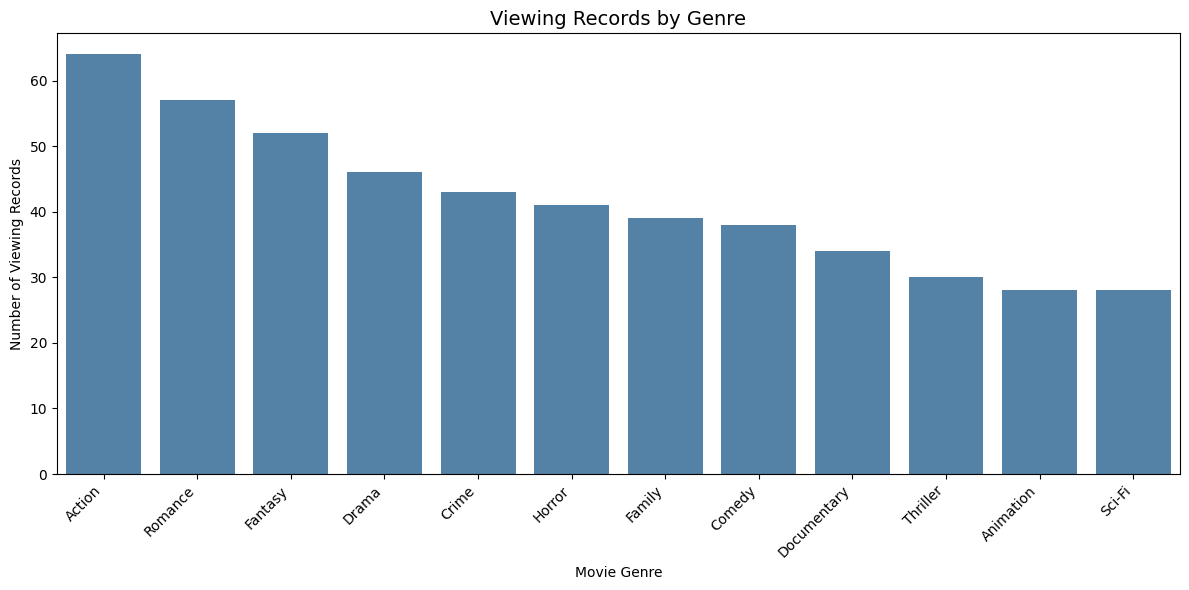

In [33]:

# Set the figure size
plt.figure(figsize=(12, 6))

# Create a bar chart using the genre summary
sns.barplot(
    data=genre_summary,
    x="Genre",
    y="Viewing_Records",
    color="steelblue"
)

# Add chart title and axis labels
plt.title("Viewing Records by Genre", fontsize=14)
plt.xlabel("Movie Genre")
plt.ylabel("Number of Viewing Records")

# Rotate genre names for readability
plt.xticks(rotation=45, ha="right")

# Adjust spacing and display the chart
plt.tight_layout()
plt.show()



#### Interpretation

The bar chart compares viewing frequency across movie genres.

Action has the highest number of viewing records (64), making it the most frequently represented genre in this sample.

This suggests that Action content may be an important category for further audience analysis.

However, viewing frequency alone does not measure user satisfaction or overall platform popularity.



### 6.2 Average User Ratings by Genre

#### What are we doing?
We are creating a horizontal bar chart to compare average user ratings across movie genres.

#### Why are we doing this?
Average ratings provide information about viewer evaluations, which may differ from viewing frequency.



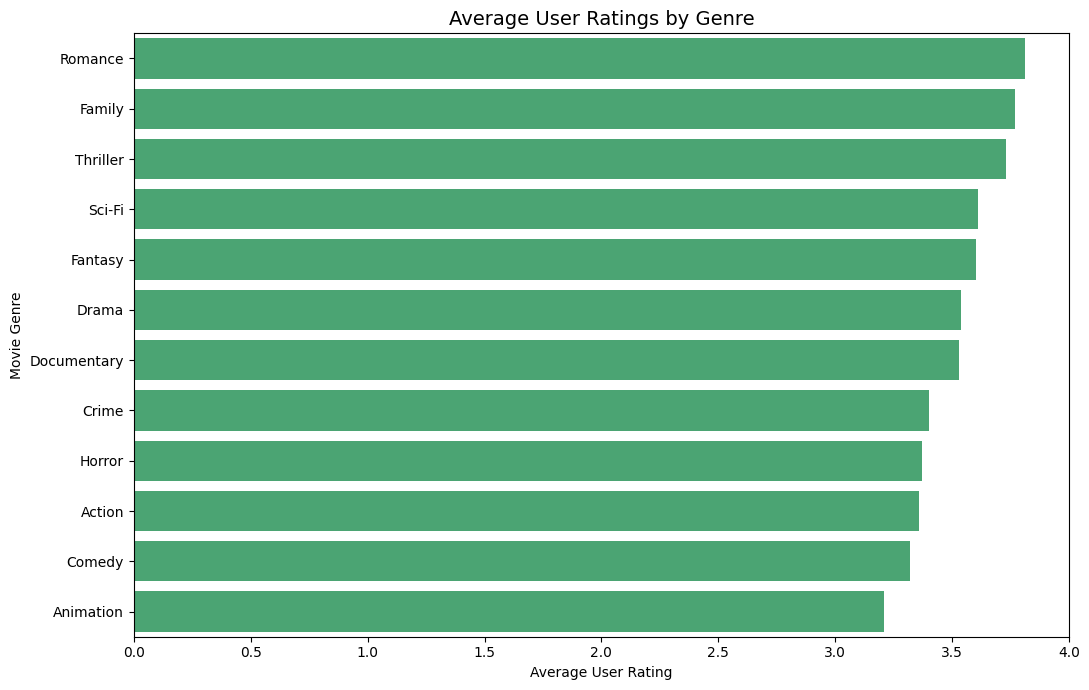

In [34]:

# Convert genre ratings into a DataFrame
genre_ratings_plot = genre_ratings.reset_index()

# Set figure size
plt.figure(figsize=(11, 7))

# Create a horizontal bar chart
sns.barplot(
    data=genre_ratings_plot,
    x="Average_User_Rating",
    y="Genre",
    color="mediumseagreen"
)

# Add chart title and labels
plt.title("Average User Ratings by Genre", fontsize=14)
plt.xlabel("Average User Rating")
plt.ylabel("Movie Genre")

# Adjust layout and display
plt.tight_layout()
plt.show()



#### Interpretation

The chart compares average user ratings across genres.

Romance received the highest average rating of approximately 3.81, based on 57 rating records.

This suggests relatively positive viewer evaluations for Romance content within the sample.

Netflix management could compare these ratings with viewing frequency when evaluating content categories.



### 6.3 Unique Users by Membership Category

#### What are we doing?
We are visualizing the number of unique users associated with each membership category.

#### Why are we doing this?
This chart helps management compare membership categories without counting repeated viewing records as separate users.



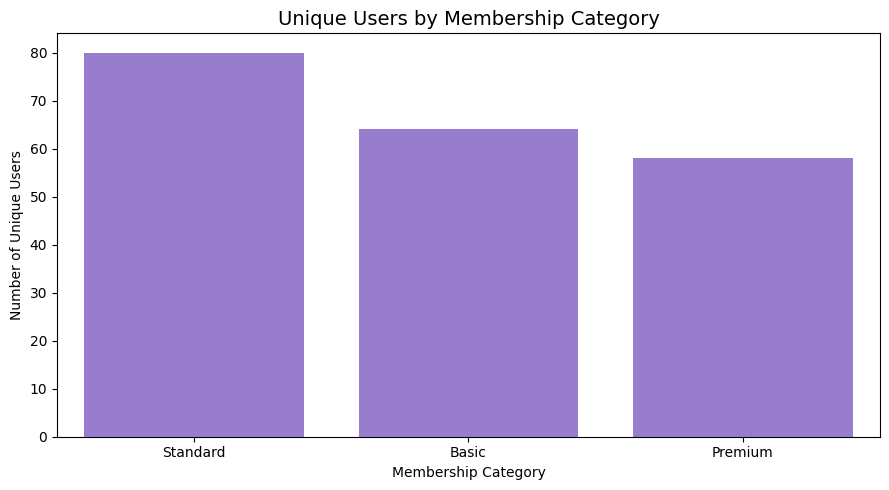

In [35]:

# Set figure size
plt.figure(figsize=(9, 5))

# Create a membership distribution bar chart
sns.barplot(
    data=membership_summary,
    x="Membership",
    y="Unique_Users",
    color="mediumpurple"
)

# Add title and labels
plt.title("Unique Users by Membership Category", fontsize=14)
plt.xlabel("Membership Category")
plt.ylabel("Number of Unique Users")

# Display chart
plt.tight_layout()
plt.show()



#### Interpretation

The chart shows the distribution of unique users across membership categories.

Standard membership has the highest number of unique users (80), followed by Basic (64) and Premium (58).

This indicates that Standard membership is the most represented category in the sample.

The result does not establish Netflix's actual subscription market share.



### 6.4 Viewing Records by Country

#### What are we doing?
We are creating a bar chart to compare viewing activity across countries.

#### Why are we doing this?
Geographical analysis helps identify which countries contribute more viewing records within the dataset.



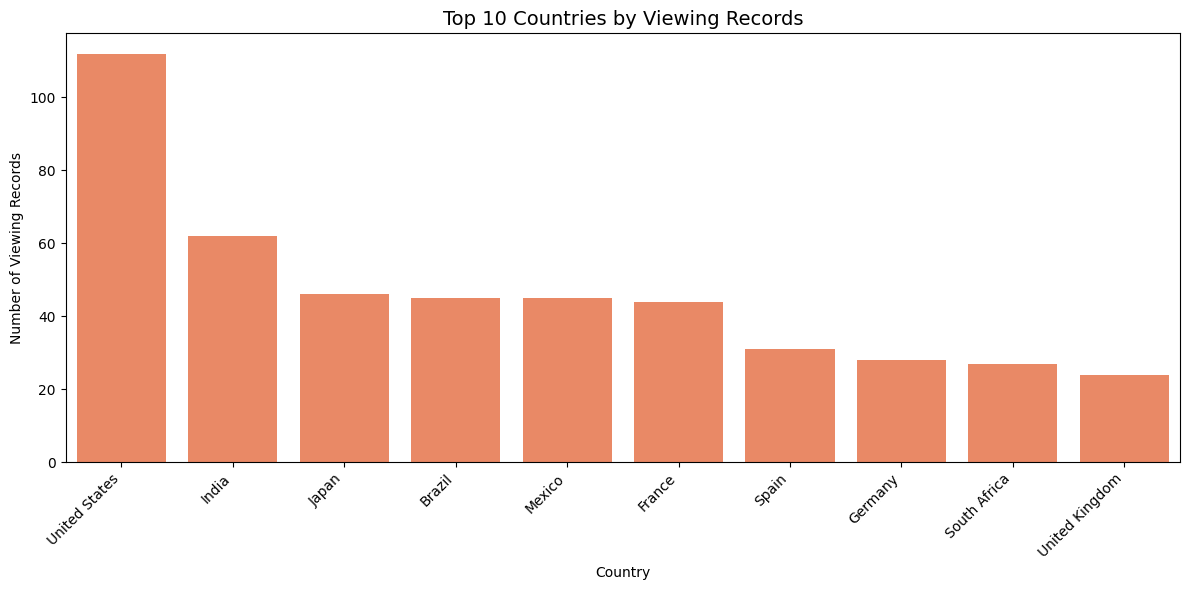

In [36]:

# Select the top 10 countries by viewing records
top_countries = country_summary.head(10)

# Set figure size
plt.figure(figsize=(12, 6))

# Create the country comparison chart
sns.barplot(
    data=top_countries,
    x="Country",
    y="Viewing_Records",
    color="coral"
)

# Add title and axis labels
plt.title("Top 10 Countries by Viewing Records", fontsize=14)
plt.xlabel("Country")
plt.ylabel("Number of Viewing Records")

# Rotate country names
plt.xticks(rotation=45, ha="right")

# Adjust layout and display
plt.tight_layout()
plt.show()



#### Interpretation

The chart compares viewing activity across the top 10 countries represented in the dataset.

The United States has the highest number of viewing records (112).

This suggests that the United States is the most frequently represented viewing country in this sample.

Further analysis would be needed to determine whether this reflects broader regional audience behavior.



### 6.5 Monthly Viewing Activity Trends

#### What are we doing?
We are creating a line chart to examine monthly changes in the number of viewing records.

#### Why are we doing this?
Time-based visualization helps identify fluctuations in viewing activity and potential seasonal patterns.



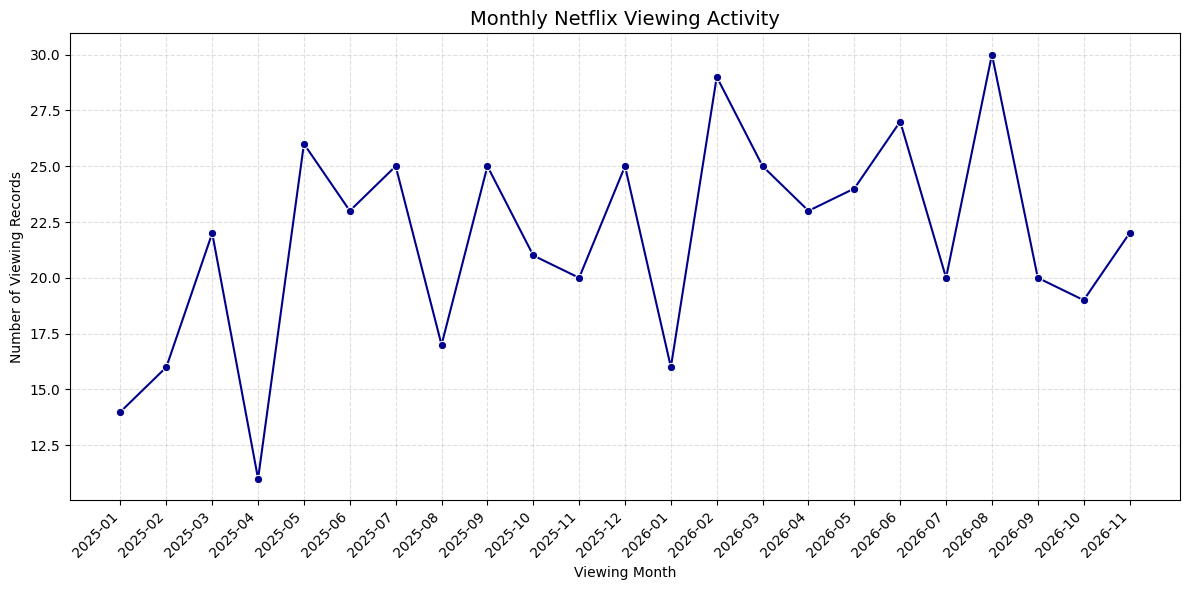

In [37]:

# Set figure size
plt.figure(figsize=(12, 6))

# Create a line chart for monthly viewing activity
sns.lineplot(
    data=monthly_viewing,
    x="Viewing_Month",
    y="Viewing_Records",
    marker="o",
    color="darkblue"
)

# Add title and axis labels
plt.title("Monthly Netflix Viewing Activity", fontsize=14)
plt.xlabel("Viewing Month")
plt.ylabel("Number of Viewing Records")

# Rotate month labels
plt.xticks(rotation=45, ha="right")

# Add grid lines for readability
plt.grid(True, linestyle="--", alpha=0.4)

# Adjust layout and display
plt.tight_layout()
plt.show()



#### Interpretation

The line chart illustrates how viewing activity changes across months.

Differences in monthly viewing counts indicate fluctuations in the number of recorded viewing observations.

Higher values represent months with more viewing records in the sample, while lower values represent months with fewer records.

Additional data would be required to determine whether these fluctuations represent seasonal trends or changes in overall Netflix engagement.



## 7. Executive Dashboard KPI Summary

### What are we doing?
We are summarizing five executive KPIs from the Netflix dataset.

### Why are we doing this?
The reference dashboard focuses on viewing activity, unique viewers, user satisfaction, estimated watching hours, and highly rated viewing records.

### Selected KPIs
1. Total Views
2. Unique Viewers
3. Average Rating
4. Estimated Hours Watched
5. Percentage of Ratings of 4 Stars or More


In [38]:

# Create five KPIs matching the reference dashboard
executive_summary = pd.DataFrame({
    "KPI": [
        "Total Views",
        "Unique Viewers",
        "Average Rating",
        "Estimated Hours Watched",
        "Rated 4 Stars or More"
    ],
    "Value": [
        len(analysis_df),
        analysis_df["User_Id"].nunique(),
        round(analysis_df["Ratings"].mean(), 2),
        round(total_hours_watched),
        f"{high_rating_percentage:.1f}%"
    ]
})

# Display the executive KPI summary
display(executive_summary)


,KPI,Value
0,Total Views,500
1,Unique Viewers,202
2,Average Rating,3.52
3,Estimated Hours Watched,938
4,Rated 4 Stars or More,49.8%



## 8. Business Insights

### What are we doing?
We are interpreting the results of exploratory data analysis and visualizations to identify meaningful business insights.

### Why are we doing this?
Business insights help transform numerical findings into information that can support management decisions.

### Insight 1: Genre Popularity
Action recorded the highest viewing frequency, with 64 viewing records.

This suggests that Action content is an important category within the sample and may deserve further audience analysis.

### Insight 2: Viewer Ratings
Romance received the highest average user rating of approximately 3.81, based on 57 rating records.

This indicates relatively positive viewer evaluations for Romance content within the dataset.

### Insight 3: Membership Distribution
Standard membership had the highest number of unique users (80), followed by Basic (64) and Premium (58).

This indicates that Standard membership is the most represented category in the sample.

### Insight 4: Geographical Viewing Activity
The United States recorded the highest viewing frequency, with 112 observations.

This suggests that the United States is the most frequently represented viewing country in the dataset.

### Insight 5: Monthly Viewing Patterns
Monthly viewing activity fluctuates across the observed period.

These variations highlight the importance of monitoring viewing trends over time.


### Additional Dashboard Insights

**Highly Rated Viewing Records:** The percentage of viewing records rated four stars or higher provides an additional measure of positive user evaluations.

**Movie-Level Performance:** Comparing the highest-rated and lowest-rated movies, with a minimum of five viewing records per movie, helps identify titles that may deserve further investigation.

**Membership and Geographic Comparisons:** The analysis compares viewing patterns across membership categories and countries using descriptive statistics and visualizations.



### Overall Interpretation
The analysis demonstrates how content preferences, user evaluations, membership categories, and viewing activity can be summarized through executive KPIs and visualizations.

All findings are based on the sample dataset and should not be generalized to Netflix's entire user population.



## 9. Business Recommendations

Based on the analysis, the following recommendations are proposed for Netflix management.

### Recommendation 1: Monitor Popular Genres
Netflix should continue monitoring viewing activity across genres, particularly Action, to understand content preferences and identify potential programming opportunities.

### Recommendation 2: Evaluate Highly Rated Content
Genres with higher average ratings, such as Romance, should be investigated further to understand the factors associated with positive viewer evaluations.

### Recommendation 3: Analyze Membership Preferences
Netflix should examine differences in viewing behavior across membership categories to better understand user engagement and potential opportunities for improving the subscriber experience.

### Recommendation 4: Explore Regional Viewing Patterns
Country-level viewing differences should be studied using larger and more representative datasets before making regional content investment decisions.

### Recommendation 5: Track Viewing Trends
Netflix should monitor monthly viewing activity over longer periods to identify meaningful changes and potential seasonal patterns.

These recommendations are exploratory and require further validation using broader Netflix data.



## 10. Project Limitations

Although the analysis provides useful insights, several limitations should be considered.

1. **Limited Sample Size:** The dataset contains only 500 viewing observations and may not represent Netflix's entire user population.

2. **Limited Business Metrics:** The dataset does not contain revenue, subscription prices, profit, or customer acquisition costs.

3. **Viewing Records vs. Actual Engagement:** Viewing records do not necessarily indicate completed viewing sessions or total watch time.

4. **Limited Generalizability:** The findings describe patterns within the provided dataset and should not be interpreted as Netflix-wide trends.

5. **No Causal Analysis:** The analysis identifies associations and descriptive patterns but does not establish why users prefer particular genres or membership categories.

Further analysis using larger and more comprehensive datasets would improve the reliability of management recommendations.



## 11. Final Conclusion

This project successfully analyzed Netflix movie ratings and viewing data to develop a management-focused executive dashboard.

The analysis followed a structured workflow consisting of data extraction, transformation, loading, exploratory data analysis, and visualization.

The dataset contained 500 viewing records, 58 unique movies, 202 unique users, and 12 genres, with an overall average user rating of approximately 3.52.

Five visualizations were developed to examine genre popularity, average user ratings, membership distribution, geographical viewing activity, and monthly viewing trends.

The findings identified Action as the most frequently viewed genre, Romance as the highest-rated genre, Standard as the most represented membership category, and the United States as the country with the highest number of viewing records.

These findings demonstrate how descriptive analytics and executive KPIs can support the interpretation of content and viewing patterns.

However, because the dataset represents a limited sample, the results should be considered exploratory rather than representative of Netflix's overall business performance.

Overall, the project demonstrates the practical application of Python, pandas, exploratory data analysis, and data visualization to support data-driven business decision-making.




In [39]:
print("All Cell Run Successfully!!!!")

All Cell Run Successfully!!!!
